# EfficientNetB0 para Beans

**Asignatura:** Inteligencia Artificial
**Proyecto:** Clasificación de enfermedades foliares de fréjol
**Grupo:** 1 · **Modelo asignado:** EfficientNetB0

## Objetivo
Entrenar EfficientNetB0 con la preparación de `Preparacion_Beans.ipynb` (224 × 224, lotes de 32
y volteo horizontal aleatorio en Train). Beans está balanceado, así que no se usa ponderación de clases.
Se comparan dos corridas: **base congelada** y **ajuste fino**.

## Preparación de los datos
Se ejecutan los pasos de `Preparacion_Beans.ipynb` sin cambios (se omiten solo las gráficas de exploración).

In [1]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

# Mostrar las versiones utilizadas en el notebook.
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("NumPy:", np.__version__)

# Consultar los dispositivos que TensorFlow puede usar.
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
NumPy: 2.5.4


GPU disponible: []

Librerías importadas correctamente.


In [2]:
# PASO 2: Carga de las particiones oficiales de Beans
from zipfile import ZipFile

# Usar la copia de los ZIP originales publicada por Makerere AI Lab.
url_base = (
    "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/"
    "27aa014ce09b193e1a6f58112d4a66e0eddb69c5/data/"
)

# Verificar que cada descarga coincide con el archivo original.
huellas_sha256 = {
    "train": "284fe8456ce20687f4367ae7ad94a64577e7f9fde2c2c6b1c74340ab5dc82715",
    "validation": "90b7aa1c26d91d9afff07a30bbc67a5ea34f1f1397f068d8675be09d7d0c602d",
    "test": "ca67b15d960d1e2fd9d23fd8498ce86818ead90755c630a43baf19ec4af09312",
}

# Mantener el mismo orden de etiquetas que usa TensorFlow Datasets.
clases = ["angular_leaf_spot", "bean_rust", "healthy"]
id_por_clase = {nombre: indice for indice, nombre in enumerate(clases)}


def cargar_particion(nombre):
    ruta_zip = tf.keras.utils.get_file(
        fname=f"{nombre}.zip",
        origin=f"{url_base}{nombre}.zip",
        file_hash=huellas_sha256[nombre],
        hash_algorithm="sha256",
        cache_subdir="datasets/beans_makerere",
    )

    with ZipFile(ruta_zip) as archivo:
        fotos = sorted(ruta for ruta in archivo.namelist() if ruta.endswith(".jpg"))

    # Leer cada foto del ZIP y obtener su etiqueta de la carpeta de origen.
    def leer_fotos():
        with ZipFile(ruta_zip) as archivo:
            for ruta in fotos:
                nombre_clase = ruta.split("/")[-2]
                yield archivo.read(ruta), id_por_clase[nombre_clase]

    dataset = tf.data.Dataset.from_generator(
        leer_fotos,
        output_signature=(tf.TensorSpec((), tf.string), tf.TensorSpec((), tf.int64)),
    )

    def decodificar_foto(imagen, etiqueta):
        return {"image": tf.io.decode_jpeg(imagen, channels=3), "label": etiqueta}

    return dataset.map(decodificar_foto), len(fotos)


ds_train, cantidad_train = cargar_particion("train")
ds_val, cantidad_val = cargar_particion("validation")
ds_test, cantidad_test = cargar_particion("test")

print(f"Entrenamiento: {cantidad_train} imágenes")
print(f"Validación: {cantidad_val} imágenes")
print(f"Prueba: {cantidad_test} imágenes")

Entrenamiento: 1034 imágenes
Validación: 133 imágenes
Prueba: 128 imágenes


In [3]:
# PASO 3: Análisis de las características y etiquetas de Beans
# Mostrar la correspondencia entre cada etiqueta numérica y su clase.
print("Clases del dataset:")
for indice, nombre in enumerate(clases):
    print(f"{indice}: {nombre}")

# Tomar una imagen de entrenamiento para revisar su formato original.
ejemplo = next(iter(ds_train.take(1)))
imagen = ejemplo["image"]
etiqueta = int(ejemplo["label"].numpy())

print("\nCaracterísticas de una imagen de entrenamiento:")
print("Dimensiones (alto, ancho, canales):", tuple(imagen.shape))
print("Tipo de dato:", imagen.dtype.name)
print("Píxel mínimo:", tf.reduce_min(imagen).numpy())
print("Píxel máximo:", tf.reduce_max(imagen).numpy())
print(f"Etiqueta: {etiqueta} ({clases[etiqueta]})")

Clases del dataset:
0: angular_leaf_spot
1: bean_rust
2: healthy

Características de una imagen de entrenamiento:
Dimensiones (alto, ancho, canales): (500, 500, 3)
Tipo de dato: uint8
Píxel mínimo: 0
Píxel máximo: 255
Etiqueta: 0 (angular_leaf_spot)


In [4]:
# PASO 3.1: Distribución de clases por partición
particiones_beans = {
    "Entrenamiento": ds_train,
    "Validación": ds_val,
    "Prueba": ds_test,
}

# Contar las imágenes de cada clase dentro de cada partición.
conteos_beans = {}

for nombre_particion, dataset in particiones_beans.items():
    conteos = np.zeros(len(clases), dtype=int)

    for registro in dataset:
        etiqueta = int(registro["label"].numpy())
        conteos[etiqueta] += 1

    conteos_beans[nombre_particion] = conteos

    total = conteos.sum()
    print(f"\n{nombre_particion}: {total} imágenes")
    for nombre_clase, cantidad in zip(clases, conteos):
        print(f"  {nombre_clase}: {cantidad} ({cantidad / total:.1%})")


Entrenamiento: 1034 imágenes
  angular_leaf_spot: 345 (33.4%)
  bean_rust: 348 (33.7%)
  healthy: 341 (33.0%)

Validación: 133 imágenes
  angular_leaf_spot: 44 (33.1%)
  bean_rust: 45 (33.8%)
  healthy: 44 (33.1%)



Prueba: 128 imágenes
  angular_leaf_spot: 43 (33.6%)
  bean_rust: 43 (33.6%)
  healthy: 42 (32.8%)


In [5]:
# PASO 5: Preparación de los datos de Beans para el entrenamiento
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def preparar_imagen(registro):
    # Aplicar la misma reducción que se revisó en el Paso 4.1.
    imagen = tf.image.resize(registro["image"], IMG_SIZE, antialias=True)
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]


def preparar_dataset(dataset, cantidad, entrenamiento=False):
    # Informar a TensorFlow cuántas imágenes entrega la partición.
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(cantidad))

    # Mezclar Train antes de formar los lotes.
    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=cantidad, seed=42, reshuffle_each_iteration=True
        )

    dataset = dataset.map(preparar_imagen, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_preparado = preparar_dataset(ds_train, cantidad_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val, cantidad_val)
test_preparado = preparar_dataset(ds_test, cantidad_test)

# Verificar un lote de Train y uno de Validation.
for nombre, dataset in [
    ("Entrenamiento", train_preparado),
    ("Validación", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))
    print(f"\n{nombre}")
    print("Dimensiones de las imágenes:", imagenes.shape)
    print("Dimensiones de las etiquetas:", etiquetas.shape)
    print("Tipo de píxeles:", imagenes.dtype.name)


Entrenamiento
Dimensiones de las imágenes: (32, 224, 224, 3)
Dimensiones de las etiquetas: (32,)
Tipo de píxeles: float32

Validación
Dimensiones de las imágenes: (32, 224, 224, 3)
Dimensiones de las etiquetas: (32,)
Tipo de píxeles: float32


In [6]:
# PASO 7: Crear una variante de Train con volteo horizontal aleatorio
volteo_horizontal = tf.keras.layers.RandomFlip(
    mode="horizontal",
    seed=42,
)

def aplicar_volteo(imagenes, etiquetas):
    # Aplicar el aumento a las imágenes y conservar sus etiquetas.
    return volteo_horizontal(imagenes, training=True), etiquetas

train_con_aumento = train_preparado.map(aplicar_volteo).prefetch(tf.data.AUTOTUNE)

print("Lotes de Train sin aumento:", int(train_preparado.cardinality().numpy()))
print("Lotes de Train con aumento:", int(train_con_aumento.cardinality().numpy()))

Lotes de Train sin aumento: 33
Lotes de Train con aumento: 33


## Funciones de entrenamiento y evaluación
EfficientNetB0 trae su propia normalización y recibe píxeles de 0 a 255, por eso no se agrega `Rescaling`.

In [7]:
# PASO 9: Funciones comunes para entrenar, guardar y evaluar EfficientNetB0
import csv
import json
from datetime import datetime
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

PRUEBA_RAPIDA = False  # True solo para comprobar el código con pocos lotes

carpeta_actual = Path.cwd()
carpeta_dataset = (
    carpeta_actual if carpeta_actual.name == "beans"
    else carpeta_actual / "beans"
)
if not (carpeta_dataset / "EfficientNetB0.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code y ejecuta desde allí.")

carpeta_resultados = carpeta_dataset / "resultados" / "efficientnetb0"


def construir_efficientnet(n_clases, nombre):
    """EfficientNetB0 preentrenado en ImageNet con una capa de salida nueva."""
    keras.utils.set_random_seed(42)
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3),
        pooling="avg",
    )
    # Fase inicial: la base queda congelada y solo aprende la capa nueva.
    base.trainable = False

    # EfficientNetB0 ya trae su propia normalización interna y espera
    # píxeles de 0 a 255, así que NO se agrega Rescaling ni Normalization.
    entrada = keras.Input(shape=(*IMG_SIZE, 3), name="imagen")
    caracteristicas = base(entrada, training=False)
    x = layers.Dropout(0.2, name="dropout")(caracteristicas)
    salida = layers.Dense(n_clases, activation="softmax", name=f"clasificacion_{nombre}")(x)
    modelo = keras.Model(entrada, salida, name=f"efficientnetb0_{nombre}")
    return modelo, base


def compilar(modelo, lr):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )


def entrenar(modelo, prefijo, epocas, pesos_clase=None, datos_train=None):
    """Entrena y guarda historial.csv y mejor_modelo.keras en su propia carpeta."""
    datos_train = train_preparado if datos_train is None else datos_train
    datos_val = val_preparado
    if PRUEBA_RAPIDA:
        datos_train, datos_val, epocas = datos_train.take(2), datos_val.take(1), 1

    nombre_corrida = datetime.now().strftime(f"{prefijo}_%Y%m%d_%H%M%S")
    carpeta = carpeta_resultados / nombre_corrida
    carpeta.mkdir(parents=True, exist_ok=False)
    ruta_modelo = carpeta / "mejor_modelo.keras"
    print("Los resultados se guardarán en", carpeta.resolve())

    modelo.fit(
        datos_train,
        validation_data=datos_val,
        epochs=epocas,
        class_weight=pesos_clase,
        callbacks=[
            # Anotar las métricas de cada época.
            keras.callbacks.CSVLogger(str(carpeta / "historial.csv")),
            # Guardar el modelo de la época con menor pérdida en Validation.
            keras.callbacks.ModelCheckpoint(
                filepath=str(ruta_modelo), monitor="val_loss",
                mode="min", save_best_only=True,
            ),
            # Detener si Validation no mejora durante dos épocas seguidas.
            keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min", patience=2,
                restore_best_weights=True,
            ),
        ],
        verbose=2,
    )
    return carpeta


def evaluar(carpeta, titulo):
    """Matriz de confusión, métricas por clase y figuras de la corrida."""
    modelo = keras.models.load_model(str(carpeta / "mejor_modelo.keras"), compile=False)
    nombres = list(clases)
    matriz = np.zeros((len(nombres), len(nombres)), dtype=int)
    datos_val = val_preparado.take(1) if PRUEBA_RAPIDA else val_preparado
    for imagenes, etiquetas in datos_val:
        predicciones = np.argmax(modelo(imagenes, training=False).numpy(), axis=1)
        np.add.at(matriz, (etiquetas.numpy(), predicciones), 1)

    aciertos = matriz.diagonal()
    reales = matriz.sum(axis=1)
    predichas = matriz.sum(axis=0)
    precision = aciertos / np.maximum(predichas, 1)
    recall = aciertos / np.maximum(reales, 1)
    f1 = 2 * aciertos / np.maximum(reales + predichas, 1)
    exactitud = aciertos.sum() / max(reales.sum(), 1)

    print("Orden de clases:", nombres)
    print("Matriz de confusión (filas reales, columnas predichas):")
    print(matriz)
    print("\nClase              Aciertos   Precisión   Recall      F1")
    for i, clase in enumerate(nombres):
        print(f"{clase:<18} {aciertos[i]:>4}/{reales[i]:<5}"
              f" {precision[i]:>9.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}")
    print(f"\nExactitud en Validation: {exactitud:.2%}")
    print(f"F1 macro: {f1.mean():.4f}")

    # Guardar las métricas en un archivo para comparar corridas.
    resumen = {
        "corrida": carpeta.name,
        "exactitud_validation": round(float(exactitud), 4),
        "f1_macro_validation": round(float(f1.mean()), 4),
        "f1_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, f1)},
        "recall_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, recall)},
        "matriz_confusion": matriz.tolist(),
    }
    (carpeta / "metricas_validation.json").write_text(
        json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")

    # Figura 1: matriz de confusión en porcentaje de cada clase real.
    porcentajes = 100 * matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7.5, 5.5), layout="constrained")
    imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
    fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")
    ax.set_xticks(range(len(nombres)), labels=nombres, rotation=20)
    ax.set_yticks(range(len(nombres)), labels=nombres)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{titulo}\nValidación · F1 macro {f1.mean():.4f}")
    for fila, columna in np.ndindex(matriz.shape):
        color = "white" if porcentajes[fila, columna] > 55 else "black"
        ax.text(columna, fila, f"{matriz[fila, columna]}\n{porcentajes[fila, columna]:.0f}%",
                ha="center", va="center", color=color, fontsize=9)
    fig.savefig(carpeta / "matriz_confusion_validation.png", dpi=150)
    plt.show()

    # Figura 2: curvas de exactitud y pérdida a partir de historial.csv.
    with (carpeta / "historial.csv").open(encoding="utf-8", newline="") as archivo:
        registros = list(csv.DictReader(archivo))
    epocas = [int(fila["epoch"]) + 1 for fila in registros]
    mejor = min(registros, key=lambda fila: float(fila["val_loss"]))
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    fig.suptitle(titulo)
    for eje, metrica, nombre_metrica in [
        (ejes[0], "accuracy", "Exactitud"), (ejes[1], "loss", "Pérdida")
    ]:
        eje.plot(epocas, [float(f[metrica]) for f in registros], marker="o", label="Train")
        eje.plot(epocas, [float(f[f"val_{metrica}"]) for f in registros], marker="o", label="Validation")
        eje.axvline(int(mejor["epoch"]) + 1, color="gray", linestyle="--", label="Mejor época")
        eje.set_title(nombre_metrica)
        eje.set_xlabel("Época")
        eje.set_xticks(epocas)
        eje.grid(alpha=0.3)
        eje.legend()
    ejes[0].set_ylim(0, 1)
    fig.savefig(carpeta / "curvas_entrenamiento.png", dpi=150)
    plt.show()
    return resumen


def ajuste_fino(carpeta_origen, prefijo, epocas, pesos_clase=None, fraccion=0.30, datos_train=None):
    """Parte del mejor modelo congelado y descongela la parte alta de la base."""
    modelo = keras.models.load_model(str(carpeta_origen / "mejor_modelo.keras"), compile=False)
    base = next(capa for capa in modelo.layers if isinstance(capa, keras.Model))
    base.trainable = True
    corte = int(len(base.layers) * (1 - fraccion))
    for i, capa in enumerate(base.layers):
        # Las capas bajas siguen congeladas y las BatchNormalization también,
        # para no desordenar las estadísticas aprendidas en ImageNet.
        capa.trainable = i >= corte and not isinstance(capa, layers.BatchNormalization)
    entrenables = sum(capa.trainable for capa in base.layers)
    print(f"Capas de la base descongeladas: {entrenables} de {len(base.layers)}")
    # Tasa de aprendizaje 10 veces menor para ajustar sin romper lo aprendido.
    compilar(modelo, 1e-4)
    return entrenar(modelo, prefijo, epocas, pesos_clase, datos_train)

print("Funciones listas. Resultados en:", carpeta_resultados.resolve())

Funciones listas. Resultados en: C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\beans\resultados\efficientnetb0


## Corrida 1 · EfficientNetB0 con la base congelada

In [8]:
# Corrida 1: base congelada, 5 épocas, Adam con lr = 0,001 y Train con volteo horizontal
modelo, base = construir_efficientnet(len(clases), "beans")
compilar(modelo, 1e-3)
print(f"Parámetros totales: {modelo.count_params():,}")
carpeta_congelada = entrenar(modelo, "corrida", epocas=5, datos_train=train_con_aumento)

Parámetros totales: 4,053,414
Los resultados se guardarán en C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\beans\resultados\efficientnetb0\corrida_20261116_204929
Epoch 1/5


C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


33/33 - 25s - 766ms/step - accuracy: 0.5725 - loss: 0.8914 - val_accuracy: 0.7519 - val_loss: 0.6676


Epoch 2/5


33/33 - 18s - 550ms/step - accuracy: 0.7534 - loss: 0.6181 - val_accuracy: 0.8271 - val_loss: 0.5362


Epoch 3/5


33/33 - 18s - 551ms/step - accuracy: 0.8250 - loss: 0.5105 - val_accuracy: 0.8647 - val_loss: 0.4594


Epoch 4/5


33/33 - 18s - 535ms/step - accuracy: 0.8404 - loss: 0.4527 - val_accuracy: 0.8271 - val_loss: 0.4285


Epoch 5/5


33/33 - 18s - 539ms/step - accuracy: 0.8530 - loss: 0.4187 - val_accuracy: 0.8872 - val_loss: 0.3834


Orden de clases: ['angular_leaf_spot', 'bean_rust', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[37  5  2]
 [ 5 40  0]
 [ 1  2 41]]

Clase              Aciertos   Precisión   Recall      F1
angular_leaf_spot    37/44       86.05%    84.09%   0.8506
bean_rust            40/45       85.11%    88.89%   0.8696
healthy              41/44       95.35%    93.18%   0.9425

Exactitud en Validation: 88.72%
F1 macro: 0.8876


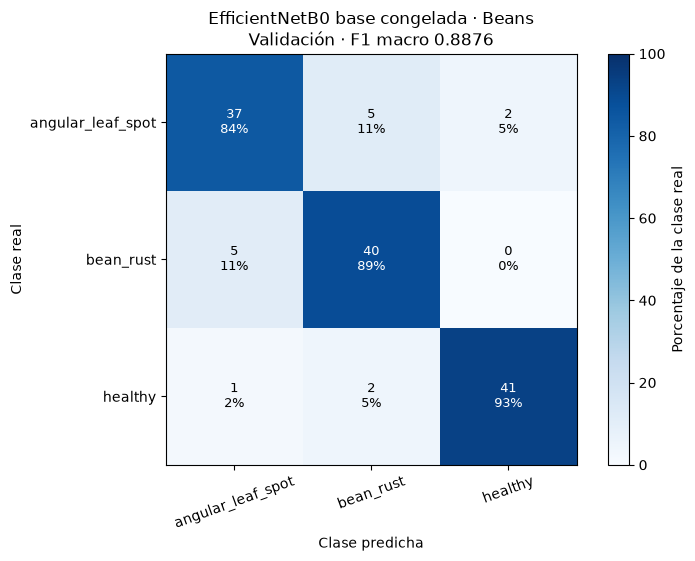

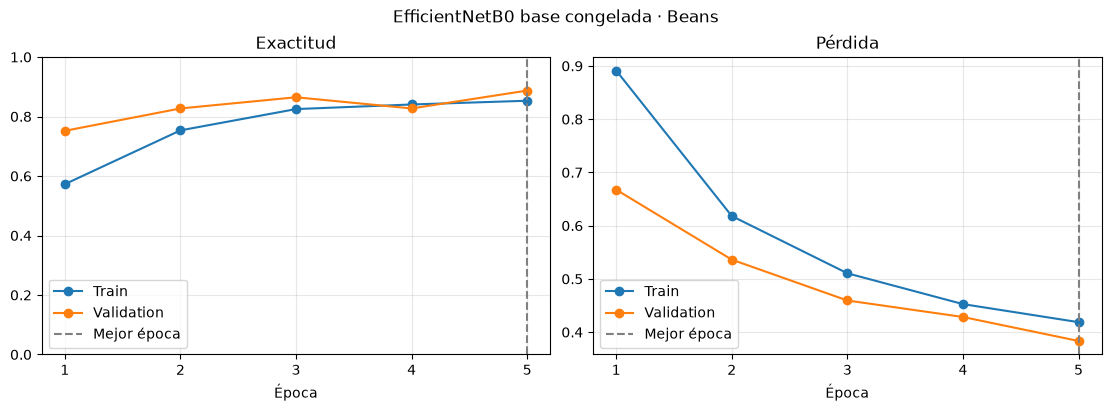

In [9]:
resumen_1 = evaluar(carpeta_congelada, "EfficientNetB0 base congelada · Beans")

## Corrida 2 · Ajuste fino
Se descongela el 30 % superior de la base y se entrena con lr = 0,0001.

In [10]:
carpeta_ajuste = ajuste_fino(carpeta_congelada, "ajuste_fino", epocas=8, datos_train=train_con_aumento)

Capas de la base descongeladas: 57 de 239
Los resultados se guardarán en C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\beans\resultados\efficientnetb0\ajuste_fino_20261116_205113
Epoch 1/8


C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


33/33 - 32s - 960ms/step - accuracy: 0.8791 - loss: 0.3116 - val_accuracy: 0.9173 - val_loss: 0.2041


Epoch 2/8


33/33 - 22s - 670ms/step - accuracy: 0.9487 - loss: 0.1507 - val_accuracy: 0.9173 - val_loss: 0.1720


Epoch 3/8


33/33 - 21s - 646ms/step - accuracy: 0.9574 - loss: 0.1177 - val_accuracy: 0.9248 - val_loss: 0.2007


Epoch 4/8


33/33 - 21s - 650ms/step - accuracy: 0.9816 - loss: 0.0691 - val_accuracy: 0.9173 - val_loss: 0.1731


Orden de clases: ['angular_leaf_spot', 'bean_rust', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[37  7  0]
 [ 1 43  1]
 [ 1  1 42]]

Clase              Aciertos   Precisión   Recall      F1
angular_leaf_spot    37/44       94.87%    84.09%   0.8916
bean_rust            43/45       84.31%    95.56%   0.8958
healthy              42/44       97.67%    95.45%   0.9655

Exactitud en Validation: 91.73%
F1 macro: 0.9176


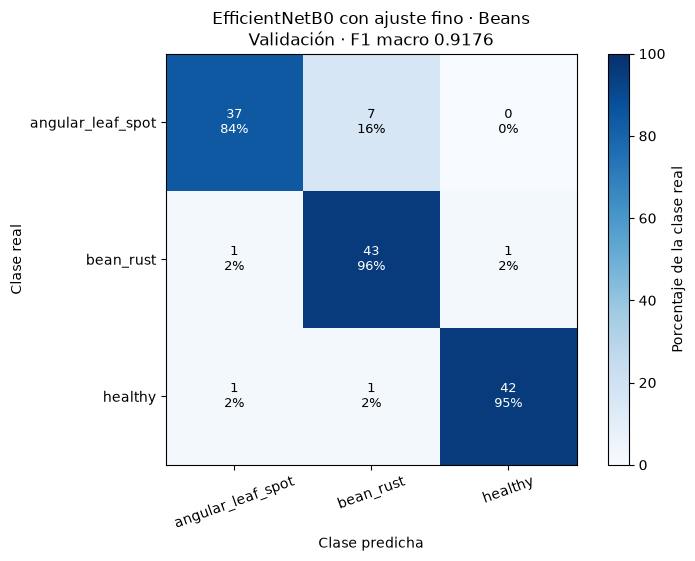

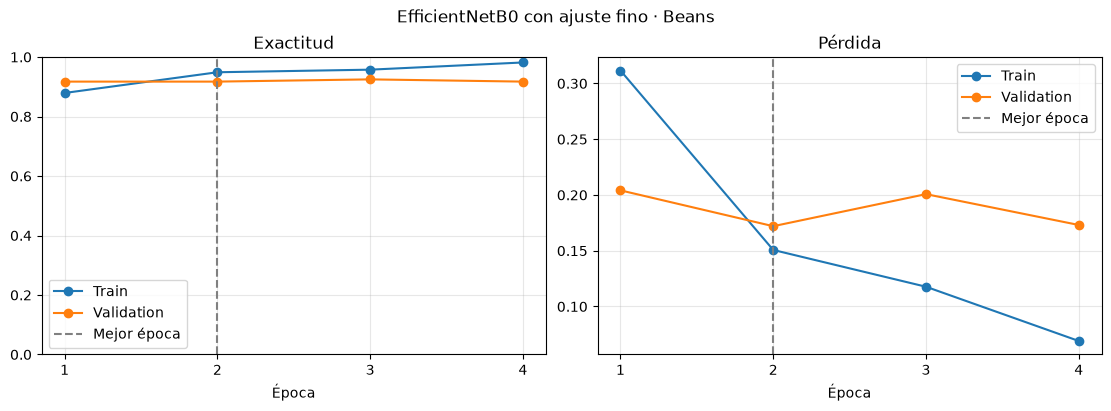

In [11]:
resumen_2 = evaluar(carpeta_ajuste, "EfficientNetB0 con ajuste fino · Beans")

## Comparación de las corridas en Validation

In [12]:
resumenes = [resumen_1, resumen_2]
for r in resumenes:
    print(f"{r['corrida']:<34} exactitud {r['exactitud_validation']:.2%} · F1 macro {r['f1_macro_validation']:.4f}")
mejor = max(resumenes, key=lambda r: r["f1_macro_validation"])
print("\nMejor corrida de EfficientNetB0 en Beans:", mejor["corrida"])
(carpeta_resultados / "comparacion_corridas.json").write_text(
    json.dumps({"mejor": mejor["corrida"], "corridas": resumenes}, indent=2, ensure_ascii=False),
    encoding="utf-8")

corrida_20261116_204929            exactitud 88.72% · F1 macro 0.8876
ajuste_fino_20261116_205113        exactitud 91.73% · F1 macro 0.9176

Mejor corrida de EfficientNetB0 en Beans: ajuste_fino_20261116_205113


1270